<a href="https://colab.research.google.com/github/ThuThaoVuong/CNN-English-Character/blob/main/CNN_English_Character.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive._mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Giới thiệu về tập dữ liệu

In [ ]:
import os
img_path='/content/drive/MyDrive/Dataset_English_Character/Img'
label_path='/content/drive/MyDrive/Dataset_English_Character/english.csv'

Tập các nhãn

In [ ]:
import pandas as pd
label=pd.read_csv(label_path)
label.head()

,image,label
0,Img/img001-001.png,0
1,Img/img001-002.png,0
2,Img/img001-003.png,0
3,Img/img001-004.png,0
4,Img/img001-005.png,0


Có tổng cộng 62 nhãn. Các nhãn là các giá trị từ A-Z, a-z, 0-9

In [ ]:
print('Số lượng nhãn:',len(label['label'].unique()))
label_output=label['label'].unique()
print('Các nhãn:',label_output)

Số lượng nhãn: 62
Các nhãn: ['0' '1' '2' '3' '4' '5' '6' '7' '8' '9' 'A' 'B' 'C' 'D' 'E' 'F' 'G' 'H'
 'I' 'J' 'K' 'L' 'M' 'N' 'O' 'P' 'Q' 'R' 'S' 'T' 'U' 'V' 'W' 'X' 'Y' 'Z'
 'a' 'b' 'c' 'd' 'e' 'f' 'g' 'h' 'i' 'j' 'k' 'l' 'm' 'n' 'o' 'p' 'q' 'r'
 's' 't' 'u' 'v' 'w' 'x' 'y' 'z']


Ứng vỡi mỗi nhãn sẽ có 55 ảnh

In [ ]:
label['label'].value_counts()

,count
label,
0,55
1,55
2,55
3,55
4,55
...,...
v,55
w,55
x,55


Tập các ảnh

In [ ]:
print('Số ảnh trong tập train:', len(os.listdir(img_path)))

Số ảnh trong tập train: 3410


Biểu diễn các ảnh và nhãn của ảnh

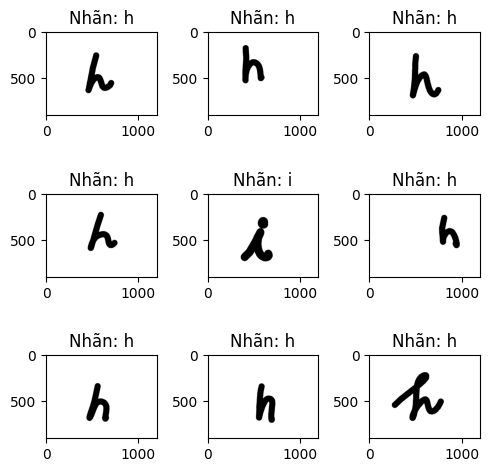

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5,5))
for i,j in enumerate(os.listdir(img_path)):
  img=plt.imread(os.path.join(img_path,j))
  plt.subplot(3,3,i+1)
  plt.imshow(img)
  plt.title('Nhãn: '+label[label['image']=='Img/'+j].label.values[0])
  if i==8: break

plt.tight_layout()
plt.show()

1 ảnh có kích thước: 1200x900, với 3 kênh màu RGB

Chi tiết ảnh (900, 1200, 3)


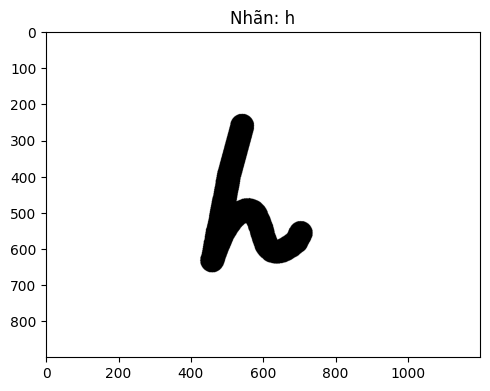

In [ ]:
import cv2

plt.figure(figsize=(5,5))
for i,j in enumerate(os.listdir(img_path)):
  img=plt.imread(os.path.join(img_path,j))
  image_detail=cv2.imread(os.path.join(img_path,j))
  print('Chi tiết ảnh',image_detail.shape)
  plt.imshow(img)
  plt.title('Nhãn: '+label[label['image']=='Img/'+j].label.values[0])
  break

plt.tight_layout()
plt.show()

Biến đổi ảnh

In [ ]:
import numpy as np

image_pre=[]
label_pre=[]

for i in os.listdir(img_path):
  img=cv2.imread(os.path.join(img_path,i)).astype('float32')
  img=cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)
  img=cv2.resize(img,(64,64))
  img/=255.0
  image_pre.append(img)
  label_pre.append(label[label['image']=='Img/'+i].label.values[0])

image_pre=np.array(image_pre)
label_pre=np.array(label_pre)

Ảnh sau khi được biến đổi

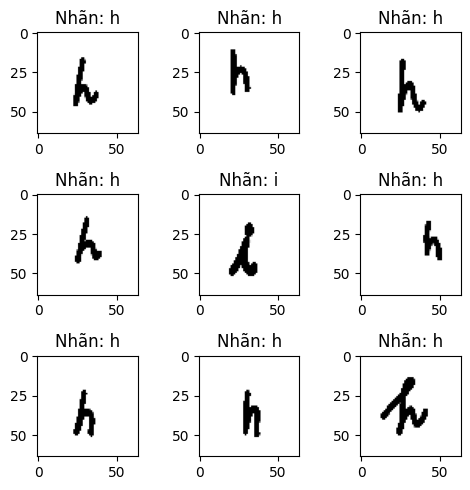

In [ ]:
plt.figure(figsize=(5,5))
for i in range(9):
  plt.subplot(3,3,i+1)
  plt.imshow(image_pre[i], cmap='gray')
  plt.title('Nhãn: '+label_pre[i])

plt.tight_layout()
plt.show()

Biến đổi nhãn từ dạng các giá trị A-Z, a-z, 0-9 về các số thứ tự từ 0-61

In [ ]:
from sklearn.preprocessing import LabelEncoder

Encoder=LabelEncoder()
label_encode=Encoder.fit_transform(label_pre)
print('Trước khi biến đổi',label_pre)
print('Sau khi biến đổi',label_encode)

Trước khi biến đổi ['h' 'h' 'h' ... '7' '6' '7']
Sau khi biến đổi [43 43 43 ...  7  6  7]


Tổng kết

In [ ]:
print('Số lượng ảnh:',len(image_pre))
print('Kích thước ảnh:',image_pre[0].shape)
print('Số lượng nhãn:', len(np.unique(label_pre)))
print('Các nhãn',np.unique(label_pre))
print('Số thứ tự ứng với các nhãn', np.unique(label_encode))

Số lượng ảnh: 3410
Kích thước ảnh: (64, 64)
Số lượng nhãn: 62
Các nhãn ['0' '1' '2' '3' '4' '5' '6' '7' '8' '9' 'A' 'B' 'C' 'D' 'E' 'F' 'G' 'H'
 'I' 'J' 'K' 'L' 'M' 'N' 'O' 'P' 'Q' 'R' 'S' 'T' 'U' 'V' 'W' 'X' 'Y' 'Z'
 'a' 'b' 'c' 'd' 'e' 'f' 'g' 'h' 'i' 'j' 'k' 'l' 'm' 'n' 'o' 'p' 'q' 'r'
 's' 't' 'u' 'v' 'w' 'x' 'y' 'z']
Số thứ tự ứng với các nhãn [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61]


Khởi tạo tập dữ liệu

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
datagen=ImageDataGenerator(rotation_range=15, width_shift_range=0.05,
                           height_shift_range=0.05, shear_range=0.2,zoom_range=0.3,
                           fill_mode='nearest')

In [ ]:
from sklearn.utils import shuffle
image_pre,label_encode=shuffle(image_pre,label_encode,random_state=42)

Chuyển label về dạng vecto

In [ ]:
from keras.utils import to_categorical
label_train=to_categorical(label_encode)
print(label_train)

[[0. 0. 1. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 1. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


In [ ]:
from sklearn.model_selection import train_test_split
x_train, x_val, y_train, y_val=train_test_split(image_pre, label_train,
                                                                  test_size=0.2, random_state=42)

In [ ]:
print('Số ảnh trong tập train:', x_train.shape)
print('Số nhãn trong tập train:', y_train.shape)
print('Số ảnh trong tập val:', x_val.shape)
print('Số nhãn trong tập val:', y_val.shape)

Số ảnh trong tập train: (2728, 64, 64)
Số nhãn trong tập train: (2728, 62)
Số ảnh trong tập val: (682, 64, 64)
Số nhãn trong tập val: (682, 62)


Tập ảnh của train được chỉnh sửa

In [ ]:
train_generator_x=[]
train_generator_y=[]
num_datagen=5
for i in range(len(x_train)):
  image=x_train[i].reshape((1,64,64,1))
  train_generator=datagen.flow(image, batch_size=1)
  for j in range(num_datagen):
    train_generator_x.append(train_generator[0][0])
    train_generator_y.append(y_train[i])

train_generator_x=np.array(train_generator_x)
train_generator_y=np.array(train_generator_y)


In [ ]:
val_generator_x=[]
val_generator_y=[]
for i in range(len(x_val)):
  image=x_val[i].reshape((1,64,64,1))
  val_generator=datagen.flow(image, batch_size=1)
  for j in range(num_datagen):
    val_generator_x.append(val_generator[0][0])
    val_generator_y.append(y_val[i])

val_generator_x=np.array(val_generator_x)
val_generator_y=np.array(val_generator_y)

In [ ]:
print('Số ảnh và kích thước ảnh trong mỗi tập',train_generator_x.shape)
print('Số nhãn và kích thước nhãn trong mỗi tập',train_generator_y.shape)
print('Số ảnh và kích thước ảnh trong mỗi tập',val_generator_x.shape)
print('Số nhãn và kích thước nhãn trong mỗi tập',val_generator_y.shape)

Số ảnh và kích thước ảnh trong mỗi tập (13640, 64, 64, 1)
Số nhãn và kích thước nhãn trong mỗi tập (13640, 62)
Số ảnh và kích thước ảnh trong mỗi tập (3410, 64, 64, 1)
Số nhãn và kích thước nhãn trong mỗi tập (3410, 62)


Biểu diễn ảnh sau khi biến đổi

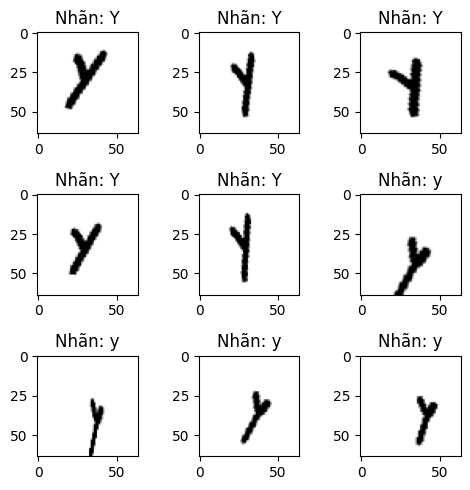

In [ ]:
plt.figure(figsize=(5,5))
for i in range(9):
  plt.subplot(3,3,i+1)
  plt.imshow(train_generator_x[i], cmap='gray')
  plt.title('Nhãn: '+label_output[np.argmax(train_generator_y[i])])

plt.tight_layout()
plt.show()

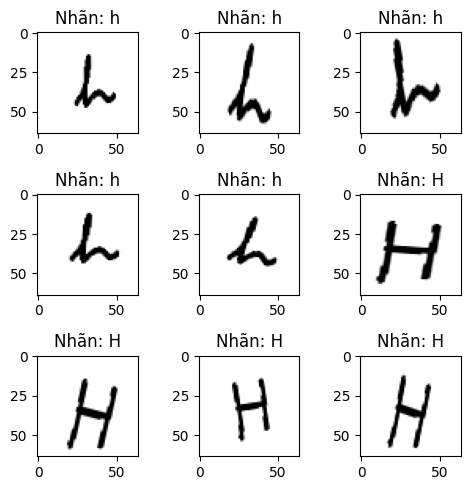

In [ ]:
plt.figure(figsize=(5,5))
for i in range(9):
  plt.subplot(3,3,i+1)
  plt.imshow(val_generator_x[i], cmap='gray')
  plt.title('Nhãn: '+label_output[np.argmax(val_generator_y[i])])

plt.tight_layout()
plt.show()

Xây dựng Model

In [ ]:
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization

Mô hình 1: activation='ReLU'

In [ ]:
model1 = Sequential()

model1.add(Conv2D(32,(3,3),activation='relu', padding='same', input_shape=(64,64,1)))
model1.add(BatchNormalization())
model1.add(Conv2D(32,(3,3),activation='relu', padding='same'))
model1.add(BatchNormalization())
model1.add(MaxPooling2D(2,2))
model1.add(Dropout(0.2))

model1.add(Conv2D(64,(3,3),activation='relu', padding='same'))
model1.add(BatchNormalization())
model1.add(Conv2D(64,(3,3),activation='relu', padding='same'))
model1.add(BatchNormalization())
model1.add(MaxPooling2D(2,2))
model1.add(Dropout(0.2))

model1.add(Conv2D(128,(3,3),activation='relu', padding='same'))
model1.add(BatchNormalization())
model1.add(Conv2D(128,(3,3),activation='relu', padding='same'))
model1.add(BatchNormalization())
model1.add(MaxPooling2D(2,2))
model1.add(Dropout(0.2))

model1.add(Flatten())
model1.add(Dense(256,activation='relu'))
model1.add(BatchNormalization())
model1.add(Dense(62,activation='softmax'))

model1.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model1.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_21 (Conv2D)              │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_21          │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 64, 64, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_22          │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_28 (Dropout)            │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_23          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_24 (Conv2D)              │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_24          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_29 (Dropout)            │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_25          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_26          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_30 (Dropout)            │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_27          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 2,402,590 (9.17 MB)

 Trainable params: 2,401,182 (9.16 MB)

 Non-trainable params: 1,408 (5.50 KB)

In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint

checkpoint = ModelCheckpoint('/content/drive/MyDrive/Dataset_English_Character/best_model1.h5', monitor='val_accuracy', save_best_only=True, verbose=1)

train_model1=model1.fit(train_generator_x,train_generator_y,
                      epochs=100, batch_size=64, callbacks=[checkpoint],
                      validation_data=(val_generator_x,val_generator_y))

Epoch 1/100
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.2942 - loss: 2.9063
Epoch 1: val_accuracy improved from -inf to 0.01349, saving model to /content/drive/MyDrive/Dataset_English_Character/best_model1.h5


214/214 ━━━━━━━━━━━━━━━━━━━━ 28s 71ms/step - accuracy: 0.2950 - loss: 2.9024 - val_accuracy: 0.0135 - val_loss: 6.0314
Epoch 2/100
213/214 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.7666 - loss: 0.8420
Epoch 2: val_accuracy improved from 0.01349 to 0.21290, saving model to /content/drive/MyDrive/Dataset_English_Character/best_model1.h5


214/214 ━━━━━━━━━━━━━━━━━━━━ 25s 32ms/step - accuracy: 0.7668 - loss: 0.8410 - val_accuracy: 0.2129 - val_loss: 3.4599
Epoch 3/100
213/214 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.8562 - loss: 0.4669
Epoch 3: val_accuracy improved from 0.21290 to 0.64692, saving model to /content/drive/MyDrive/Dataset_English_Character/best_model1.h5


214/214 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - accuracy: 0.8562 - loss: 0.4667 - val_accuracy: 0.6469 - val_loss: 1.2597
Epoch 4/100
212/214 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.8952 - loss: 0.3404
Epoch 4: val_accuracy did not improve from 0.64692
214/214 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - accuracy: 0.8952 - loss: 0.3401 - val_accuracy: 0.6026 - val_loss: 2.4803
Epoch 5/100
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9167 - loss: 0.2638
Epoch 5: val_accuracy did not improve from 0.64692
214/214 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - accuracy: 0.9167 - loss: 0.2638 - val_accuracy: 0.2584 - val_loss: 15.2807
Epoch 6/100
212/214 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9353 - loss: 0.1949
Epoch 6: val_accuracy did not improve from 0.64692
214/214 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - accuracy: 0.9353 - loss: 0.1949 - val_accuracy: 0.1543 - val_loss: 20.2984
Epoch 7/100
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9398 - loss: 0.1726
Epoch 7: val_accuracy

214/214 ━━━━━━━━━━━━━━━━━━━━ 6s 29ms/step - accuracy: 0.9558 - loss: 0.1374 - val_accuracy: 0.6918 - val_loss: 1.7362
Epoch 11/100
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9622 - loss: 0.1133
Epoch 11: val_accuracy improved from 0.69179 to 0.77097, saving model to /content/drive/MyDrive/Dataset_English_Character/best_model1.h5


...

214/214 ━━━━━━━━━━━━━━━━━━━━ 6s 29ms/step - accuracy: 0.9845 - loss: 0.0439 - val_accuracy: 0.7777 - val_loss: 1.0849
Epoch 22/100
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9889 - loss: 0.0367
Epoch 22: val_accuracy did not improve from 0.77771
214/214 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - accuracy: 0.9889 - loss: 0.0367 - val_accuracy: 0.2581 - val_loss: 9.5921
Epoch 23/100
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9861 - loss: 0.0484
Epoch 23: val_accuracy did not improve from 0.77771
214/214 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.9861 - loss: 0.0484 - val_accuracy: 0.7736 - val_loss: 1.1760
Epoch 24/100
213/214 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9794 - loss: 0.0624
Epoch 24: val_accuracy did not improve from 0.77771
214/214 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - accuracy: 0.9794 - loss: 0.0623 - val_accuracy: 0.6276 - val_loss: 2.3066
Epoch 25/100
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9930 - loss: 0.0272
Epoch 25: val_ac

214/214 ━━━━━━━━━━━━━━━━━━━━ 7s 30ms/step - accuracy: 0.9935 - loss: 0.0232 - val_accuracy: 0.7801 - val_loss: 1.0347
Epoch 28/100
213/214 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9932 - loss: 0.0218
Epoch 28: val_accuracy did not improve from 0.78006
214/214 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - accuracy: 0.9932 - loss: 0.0219 - val_accuracy: 0.3971 - val_loss: 4.6326
Epoch 29/100
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9935 - loss: 0.0206
Epoch 29: val_accuracy did not improve from 0.78006
214/214 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.9935 - loss: 0.0206 - val_accuracy: 0.4223 - val_loss: 4.1829
Epoch 30/100
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9930 - loss: 0.0214
Epoch 30: val_accuracy did not improve from 0.78006
214/214 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.9930 - loss: 0.0214 - val_accuracy: 0.0663 - val_loss: 31.2197
Epoch 31/100
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9892 - loss: 0.0340
Epoch 31: val_a

214/214 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - accuracy: 0.9847 - loss: 0.0470 - val_accuracy: 0.8009 - val_loss: 1.1357
Epoch 48/100
212/214 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9882 - loss: 0.0363
Epoch 48: val_accuracy did not improve from 0.80088
214/214 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - accuracy: 0.9882 - loss: 0.0361 - val_accuracy: 0.7487 - val_loss: 1.2927
Epoch 49/100
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9960 - loss: 0.0140
Epoch 49: val_accuracy did not improve from 0.80088
214/214 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - accuracy: 0.9960 - loss: 0.0140 - val_accuracy: 0.5771 - val_loss: 2.1778
Epoch 50/100
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9918 - loss: 0.0297
Epoch 50: val_accuracy did not improve from 0.80088
214/214 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.9918 - loss: 0.0297 - val_accuracy: 0.3856 - val_loss: 6.0490
Epoch 51/100
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9945 - loss: 0.0167
Epoch 51: val_ac

214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.9963 - loss: 0.0120 - val_accuracy: 0.8059 - val_loss: 1.2162
Epoch 56/100
212/214 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9938 - loss: 0.0199
Epoch 56: val_accuracy did not improve from 0.80587
214/214 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - accuracy: 0.9938 - loss: 0.0199 - val_accuracy: 0.6537 - val_loss: 2.2482
Epoch 57/100
212/214 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9960 - loss: 0.0138
Epoch 57: val_accuracy did not improve from 0.80587
214/214 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - accuracy: 0.9960 - loss: 0.0138 - val_accuracy: 0.6947 - val_loss: 1.9654
Epoch 58/100
212/214 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9972 - loss: 0.0096
Epoch 58: val_accuracy did not improve from 0.80587
214/214 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - accuracy: 0.9972 - loss: 0.0095 - val_accuracy: 0.6616 - val_loss: 2.3480
Epoch 59/100
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9928 - loss: 0.0233
Epoch 59: val

214/214 ━━━━━━━━━━━━━━━━━━━━ 7s 31ms/step - accuracy: 0.9975 - loss: 0.0078 - val_accuracy: 0.8117 - val_loss: 1.3006
Epoch 82/100
212/214 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9982 - loss: 0.0059
Epoch 82: val_accuracy did not improve from 0.81173
214/214 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - accuracy: 0.9982 - loss: 0.0059 - val_accuracy: 0.8050 - val_loss: 1.3661
Epoch 83/100
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9983 - loss: 0.0054
Epoch 83: val_accuracy did not improve from 0.81173
214/214 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - accuracy: 0.9983 - loss: 0.0054 - val_accuracy: 0.7182 - val_loss: 1.6907
Epoch 84/100
212/214 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9984 - loss: 0.0067
Epoch 84: val_accuracy did not improve from 0.81173
214/214 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - accuracy: 0.9984 - loss: 0.0067 - val_accuracy: 0.7188 - val_loss: 1.6810
Epoch 85/100
212/214 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9956 - loss: 0.0187
Epoch 85: val_ac

Đánh giá mô hình 1

<Figure size 1000x500 with 0 Axes>

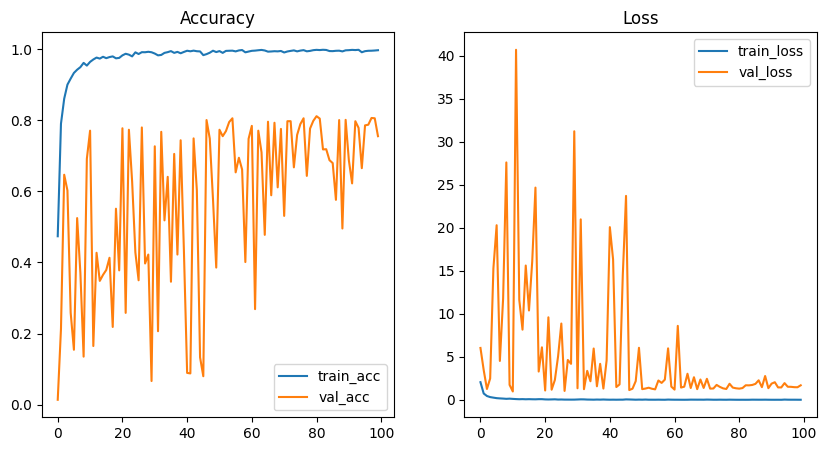

In [ ]:
plt.figure(figsize=(10,5))
train_acc=train_model1.history['accuracy']
val_acc=train_model1.history['val_accuracy']
train_loss=train_model1.history['loss']
val_loss=train_model1.history['val_loss']
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.plot(train_acc,label='train_acc')
plt.plot(val_acc,label='val_acc')
plt.title('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(train_loss,label='train_loss')
plt.plot(val_loss,label='val_loss')
plt.legend()
plt.title('Loss')
plt.show()

Model 2: activation='ELU'

In [ ]:
model2 = Sequential()

model2.add(Conv2D(32,(3,3),activation='elu', padding='same', input_shape=(64,64,1)))
model2.add(BatchNormalization())
model2.add(Conv2D(32,(3,3),activation='elu', padding='same'))
model2.add(BatchNormalization())
model2.add(MaxPooling2D(2,2))
model2.add(Dropout(0.2))

model2.add(Conv2D(64,(3,3),activation='elu', padding='same'))
model2.add(BatchNormalization())
model2.add(Conv2D(64,(3,3),activation='elu', padding='same'))
model2.add(BatchNormalization())
model2.add(MaxPooling2D(2,2))
model2.add(Dropout(0.2))

model2.add(Conv2D(128,(3,3),activation='elu', padding='same'))
model2.add(BatchNormalization())
model2.add(Conv2D(128,(3,3),activation='elu', padding='same'))
model2.add(BatchNormalization())
model2.add(MaxPooling2D(2,2))
model2.add(Dropout(0.2))

model2.add(Flatten())
model2.add(Dense(256,activation='elu'))
model2.add(BatchNormalization())
model2.add(Dense(62,activation='softmax'))

model2.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])

In [ ]:
model2.summary()

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_39 (Conv2D)              │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_42          │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_40 (Conv2D)              │ (None, 64, 64, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_43          │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_24 (MaxPooling2D) │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_37 (Dropout)            │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_41 (Conv2D)              │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_44          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_42 (Conv2D)              │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_45          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_25 (MaxPooling2D) │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_38 (Dropout)            │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_43 (Conv2D)              │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_46          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_44 (Conv2D)              │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_47          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_26 (MaxPooling2D) │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_39 (Dropout)            │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_9 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_48          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 2,402,590 (9.17 MB)

 Trainable params: 2,401,182 (9.16 MB)

 Non-trainable params: 1,408 (5.50 KB)

In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint

checkpoint = ModelCheckpoint('/content/drive/MyDrive/Dataset_English_Character/best_model2.h5', monitor='val_accuracy', save_best_only=True, verbose=1)

train_model2=model2.fit(train_generator_x,train_generator_y,
                      epochs=100, batch_size=64, callbacks=[checkpoint],
                      validation_data=(val_generator_x,val_generator_y))

Epoch 1/100
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.3056 - loss: 2.8811
Epoch 1: val_accuracy improved from -inf to 0.05073, saving model to /content/drive/MyDrive/Dataset_English_Character/best_model2.h5


214/214 ━━━━━━━━━━━━━━━━━━━━ 24s 63ms/step - accuracy: 0.3064 - loss: 2.8771 - val_accuracy: 0.0507 - val_loss: 6.2467
Epoch 2/100
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.7673 - loss: 0.8386
Epoch 2: val_accuracy improved from 0.05073 to 0.17742, saving model to /content/drive/MyDrive/Dataset_English_Character/best_model2.h5


214/214 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.7674 - loss: 0.8382 - val_accuracy: 0.1774 - val_loss: 5.1550
Epoch 3/100
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.8562 - loss: 0.4771
Epoch 3: val_accuracy improved from 0.17742 to 0.57067, saving model to /content/drive/MyDrive/Dataset_English_Character/best_model2.h5


214/214 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - accuracy: 0.8563 - loss: 0.4770 - val_accuracy: 0.5707 - val_loss: 2.2166
Epoch 4/100
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9009 - loss: 0.3113
Epoch 4: val_accuracy did not improve from 0.57067
214/214 ━━━━━━━━━━━━━━━━━━━━ 10s 27ms/step - accuracy: 0.9009 - loss: 0.3113 - val_accuracy: 0.5114 - val_loss: 2.1001
Epoch 5/100
213/214 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9273 - loss: 0.2366
Epoch 5: val_accuracy did not improve from 0.57067
214/214 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - accuracy: 0.9274 - loss: 0.2365 - val_accuracy: 0.2765 - val_loss: 4.9903
Epoch 6/100
212/214 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9443 - loss: 0.1723
Epoch 6: val_accuracy did not improve from 0.57067
214/214 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - accuracy: 0.9443 - loss: 0.1724 - val_accuracy: 0.4226 - val_loss: 3.7613
Epoch 7/100
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9449 - loss: 0.1585
Epoch 7: val_accurac

214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - accuracy: 0.9449 - loss: 0.1584 - val_accuracy: 0.6941 - val_loss: 1.3704
Epoch 8/100
212/214 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9642 - loss: 0.1142
Epoch 8: val_accuracy improved from 0.69413 to 0.73402, saving model to /content/drive/MyDrive/Dataset_English_Character/best_model2.h5


...

214/214 ━━━━━━━━━━━━━━━━━━━━ 7s 31ms/step - accuracy: 0.9878 - loss: 0.0366 - val_accuracy: 0.7680 - val_loss: 1.3455
Epoch 30/100
212/214 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9823 - loss: 0.0534
Epoch 30: val_accuracy did not improve from 0.76804
214/214 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - accuracy: 0.9823 - loss: 0.0533 - val_accuracy: 0.7575 - val_loss: 1.4345
Epoch 31/100
212/214 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9908 - loss: 0.0273
Epoch 31: val_accuracy did not improve from 0.76804
214/214 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.9908 - loss: 0.0273 - val_accuracy: 0.6537 - val_loss: 1.8584
Epoch 32/100
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9934 - loss: 0.0218
Epoch 32: val_accuracy did not improve from 0.76804
214/214 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - accuracy: 0.9934 - loss: 0.0218 - val_accuracy: 0.6123 - val_loss: 2.3296
Epoch 33/100
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9942 - loss: 0.0221
Epoch 33: val_ac

214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.9949 - loss: 0.0173 - val_accuracy: 0.7783 - val_loss: 1.4709
Epoch 46/100
213/214 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9922 - loss: 0.0242
Epoch 46: val_accuracy did not improve from 0.77830
214/214 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - accuracy: 0.9922 - loss: 0.0242 - val_accuracy: 0.5443 - val_loss: 3.2471
Epoch 47/100
213/214 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9879 - loss: 0.0336
Epoch 47: val_accuracy did not improve from 0.77830
214/214 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - accuracy: 0.9879 - loss: 0.0336 - val_accuracy: 0.7748 - val_loss: 1.5669
Epoch 48/100
212/214 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9921 - loss: 0.0273
Epoch 48: val_accuracy did not improve from 0.77830
214/214 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - accuracy: 0.9921 - loss: 0.0273 - val_accuracy: 0.6258 - val_loss: 2.3777
Epoch 49/100
213/214 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9956 - loss: 0.0133
Epoch 49: val_a

214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.9956 - loss: 0.0133 - val_accuracy: 0.7850 - val_loss: 1.3044
Epoch 50/100
212/214 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9962 - loss: 0.0102
Epoch 50: val_accuracy did not improve from 0.78504
214/214 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.9962 - loss: 0.0102 - val_accuracy: 0.7680 - val_loss: 1.4309
Epoch 51/100
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9973 - loss: 0.0090
Epoch 51: val_accuracy did not improve from 0.78504
214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - accuracy: 0.9973 - loss: 0.0091 - val_accuracy: 0.6789 - val_loss: 2.0818
Epoch 52/100
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9970 - loss: 0.0099
Epoch 52: val_accuracy did not improve from 0.78504
214/214 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.9970 - loss: 0.0099 - val_accuracy: 0.7111 - val_loss: 1.9443
Epoch 53/100
212/214 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9978 - loss: 0.0075
Epoch 53: val_

214/214 ━━━━━━━━━━━━━━━━━━━━ 7s 33ms/step - accuracy: 0.9963 - loss: 0.0098 - val_accuracy: 0.7865 - val_loss: 1.3490
Epoch 65/100
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9967 - loss: 0.0134
Epoch 65: val_accuracy improved from 0.78651 to 0.79326, saving model to /content/drive/MyDrive/Dataset_English_Character/best_model2.h5


214/214 ━━━━━━━━━━━━━━━━━━━━ 9s 27ms/step - accuracy: 0.9967 - loss: 0.0134 - val_accuracy: 0.7933 - val_loss: 1.3454
Epoch 66/100
212/214 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9974 - loss: 0.0087
Epoch 66: val_accuracy did not improve from 0.79326
214/214 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - accuracy: 0.9974 - loss: 0.0086 - val_accuracy: 0.5079 - val_loss: 3.3739
Epoch 67/100
212/214 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9988 - loss: 0.0040
Epoch 67: val_accuracy did not improve from 0.79326
214/214 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - accuracy: 0.9988 - loss: 0.0040 - val_accuracy: 0.7859 - val_loss: 1.5214
Epoch 68/100
213/214 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9983 - loss: 0.0077
Epoch 68: val_accuracy did not improve from 0.79326
214/214 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - accuracy: 0.9983 - loss: 0.0077 - val_accuracy: 0.5827 - val_loss: 2.9607
Epoch 69/100
213/214 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9865 - loss: 0.0402
Epoch 69: val_

<Figure size 1000x500 with 0 Axes>

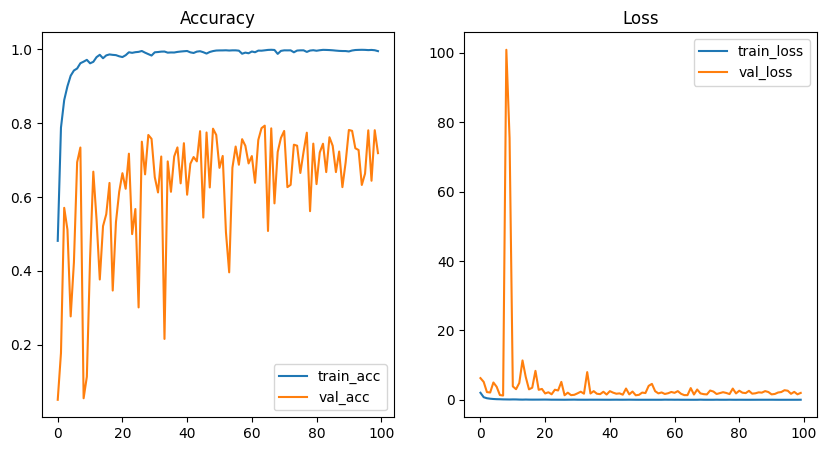

In [ ]:
plt.figure(figsize=(10,5))
train_acc=train_model2.history['accuracy']
val_acc=train_model2.history['val_accuracy']
train_loss=train_model2.history['loss']
val_loss=train_model2.history['val_loss']
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.plot(train_acc,label='train_acc')
plt.plot(val_acc,label='val_acc')
plt.title('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(train_loss,label='train_loss')
plt.plot(val_loss,label='val_loss')
plt.legend()
plt.title('Loss')
plt.show()

Dự đoán ảnh

107/107 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


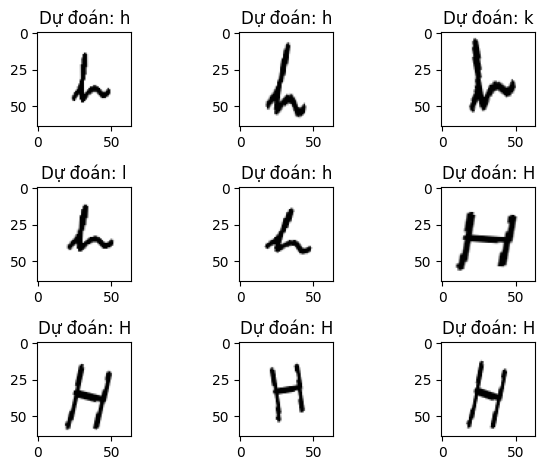

In [ ]:
model1.predict(val_generator_x)

for i in range(9):
  plt.subplot(3,3,i+1)
  plt.imshow(val_generator_x[i], cmap='gray')
  plt.title('Dự đoán: '+label_output[np.argmax(model1.predict(val_generator_x)[i])])

plt.tight_layout()
plt.show()

107/107 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
107/107 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


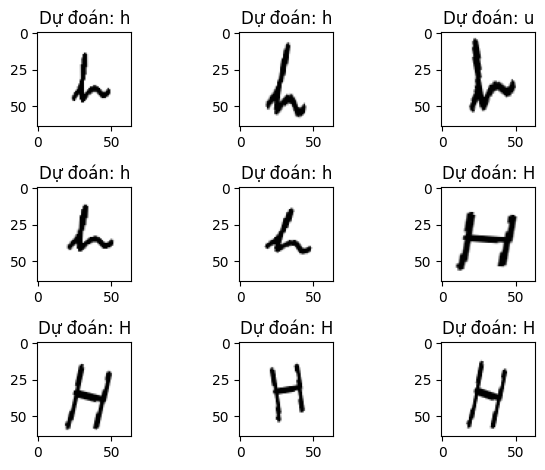

In [ ]:
model2.predict(val_generator_x)

for i in range(9):
  plt.subplot(3,3,i+1)
  plt.imshow(val_generator_x[i], cmap='gray')
  plt.title('Dự đoán: '+label_output[np.argmax(model2.predict(val_generator_x)[i])])

plt.tight_layout()
plt.show()

In [ ]:
model.save('/content/drive/MyDrive/Dataset_English_Character/model_english_character_3_elu.h5')
